In [2]:
import pymc as pm
import pytensor.tensor as at
import numpy as np
import arviz as az
import pandas as pd
import matplotlib.pyplot as plt
from pytensor.tensor.random.utils import params_broadcast_shapes

# Continuous A

In [22]:
# ---------- constants ----------
# latent sample size
n         = 100           
Xo_obs    = 1.37
Predo_obs = 2.11
tiny      = 1e-3

def define_model():   
    
    with pm.Model() as m:

        # hyper‑priors
        αXμ  = pm.Normal('αXμ',  10, 5)
        αXσ  = pm.Exponential('αXσ', 1)
        αAμ  = pm.Normal('αAμ',  5, 1)
        αYσ  = pm.Exponential('αYσ', 1)
        NE   = pm.Normal('NE',  -0.1, 1)
    
        # deterministic helpers
        a  = pm.Deterministic('a', 1 + NE)
        b  = pm.Deterministic('b', NE * αAμ)
        sy2 = pm.Deterministic('sy2', NE**2 + αYσ**2)
    
        # ── draw the three low‑dimensional auxiliaries ───────────────
        T1 = pm.Normal('T1',  0, 1,  shape=())   # will be scaled by sqrt(n)
        T2 = pm.ChiSquared('T2', n)
        T3 = pm.Normal('T3',  0, 1,  shape=())
    
        # scale them (see derivation)
        T1s = at.sqrt(n) * T1
        T3s = at.sqrt(n) * T3
    
        sx2 = αXσ**2
        deltax = αXμ / αXσ
    
        Sxx = pm.Deterministic(
            'Sxx', 
            sx2 * (n*deltax**2 + 2*deltax*T1s + T2)
        )
        Sxy = pm.Deterministic(
            'Sxy',
            a*Sxx + b*n*αXμ + b*αXσ*T1s + αXσ*at.sqrt(sy2)*T3s
        )
    
        phi = pm.Deterministic('phi', Sxy / Sxx)
    
        # only observed data in the entire model
        pm.Normal('Predo', mu = phi * Xo_obs, sigma = tiny, observed = Predo_obs)
    
    return m

In [7]:
trace

Inference data with groups:
	> posterior
	> sample_stats
	> observed_data

In [23]:
m = define_model()
with m:
    trace = pm.sample(3000, target_accept=.97, chains=4, random_seed=42)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [αXμ, αXσ, αAμ, αYσ, NE, T1, T2, T3]


Output()

Sampling 4 chains for 1_000 tune and 3_000 draw iterations (4_000 + 12_000 draws total) took 199 seconds.
There were 191 divergences after tuning. Increase `target_accept` or reparameterize.
Chain 2 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 3 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.


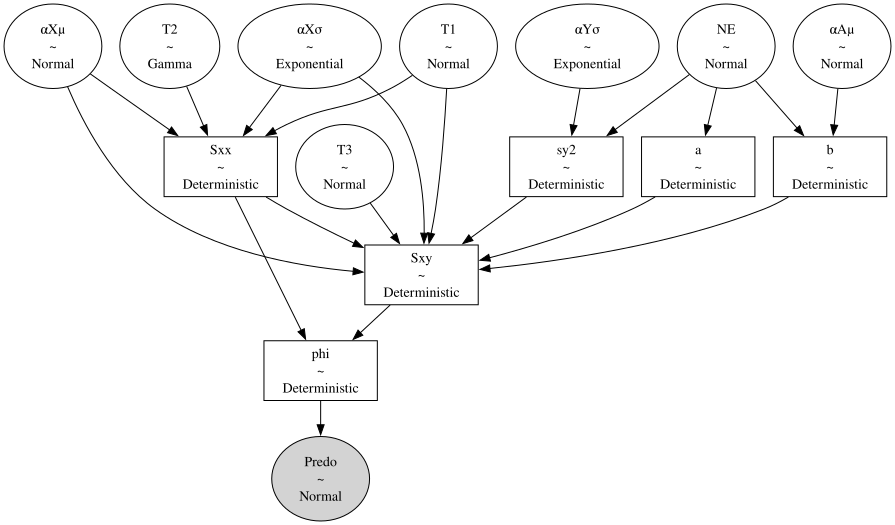

In [15]:
pm.model_to_graphviz(m)

array([[<Axes: title={'center': 'αXμ'}>, <Axes: title={'center': 'αAμ'}>,
        <Axes: title={'center': 'NE'}>, <Axes: title={'center': 'T1'}>],
       [<Axes: title={'center': 'T3'}>, <Axes: title={'center': 'αXσ'}>,
        <Axes: title={'center': 'αYσ'}>, <Axes: title={'center': 'T2'}>],
       [<Axes: title={'center': 'a'}>, <Axes: title={'center': 'b'}>,
        <Axes: title={'center': 'sy2'}>, <Axes: title={'center': 'Sxx'}>],
       [<Axes: title={'center': 'Sxy'}>, <Axes: title={'center': 'phi'}>,
        <Axes: >, <Axes: >]], dtype=object)

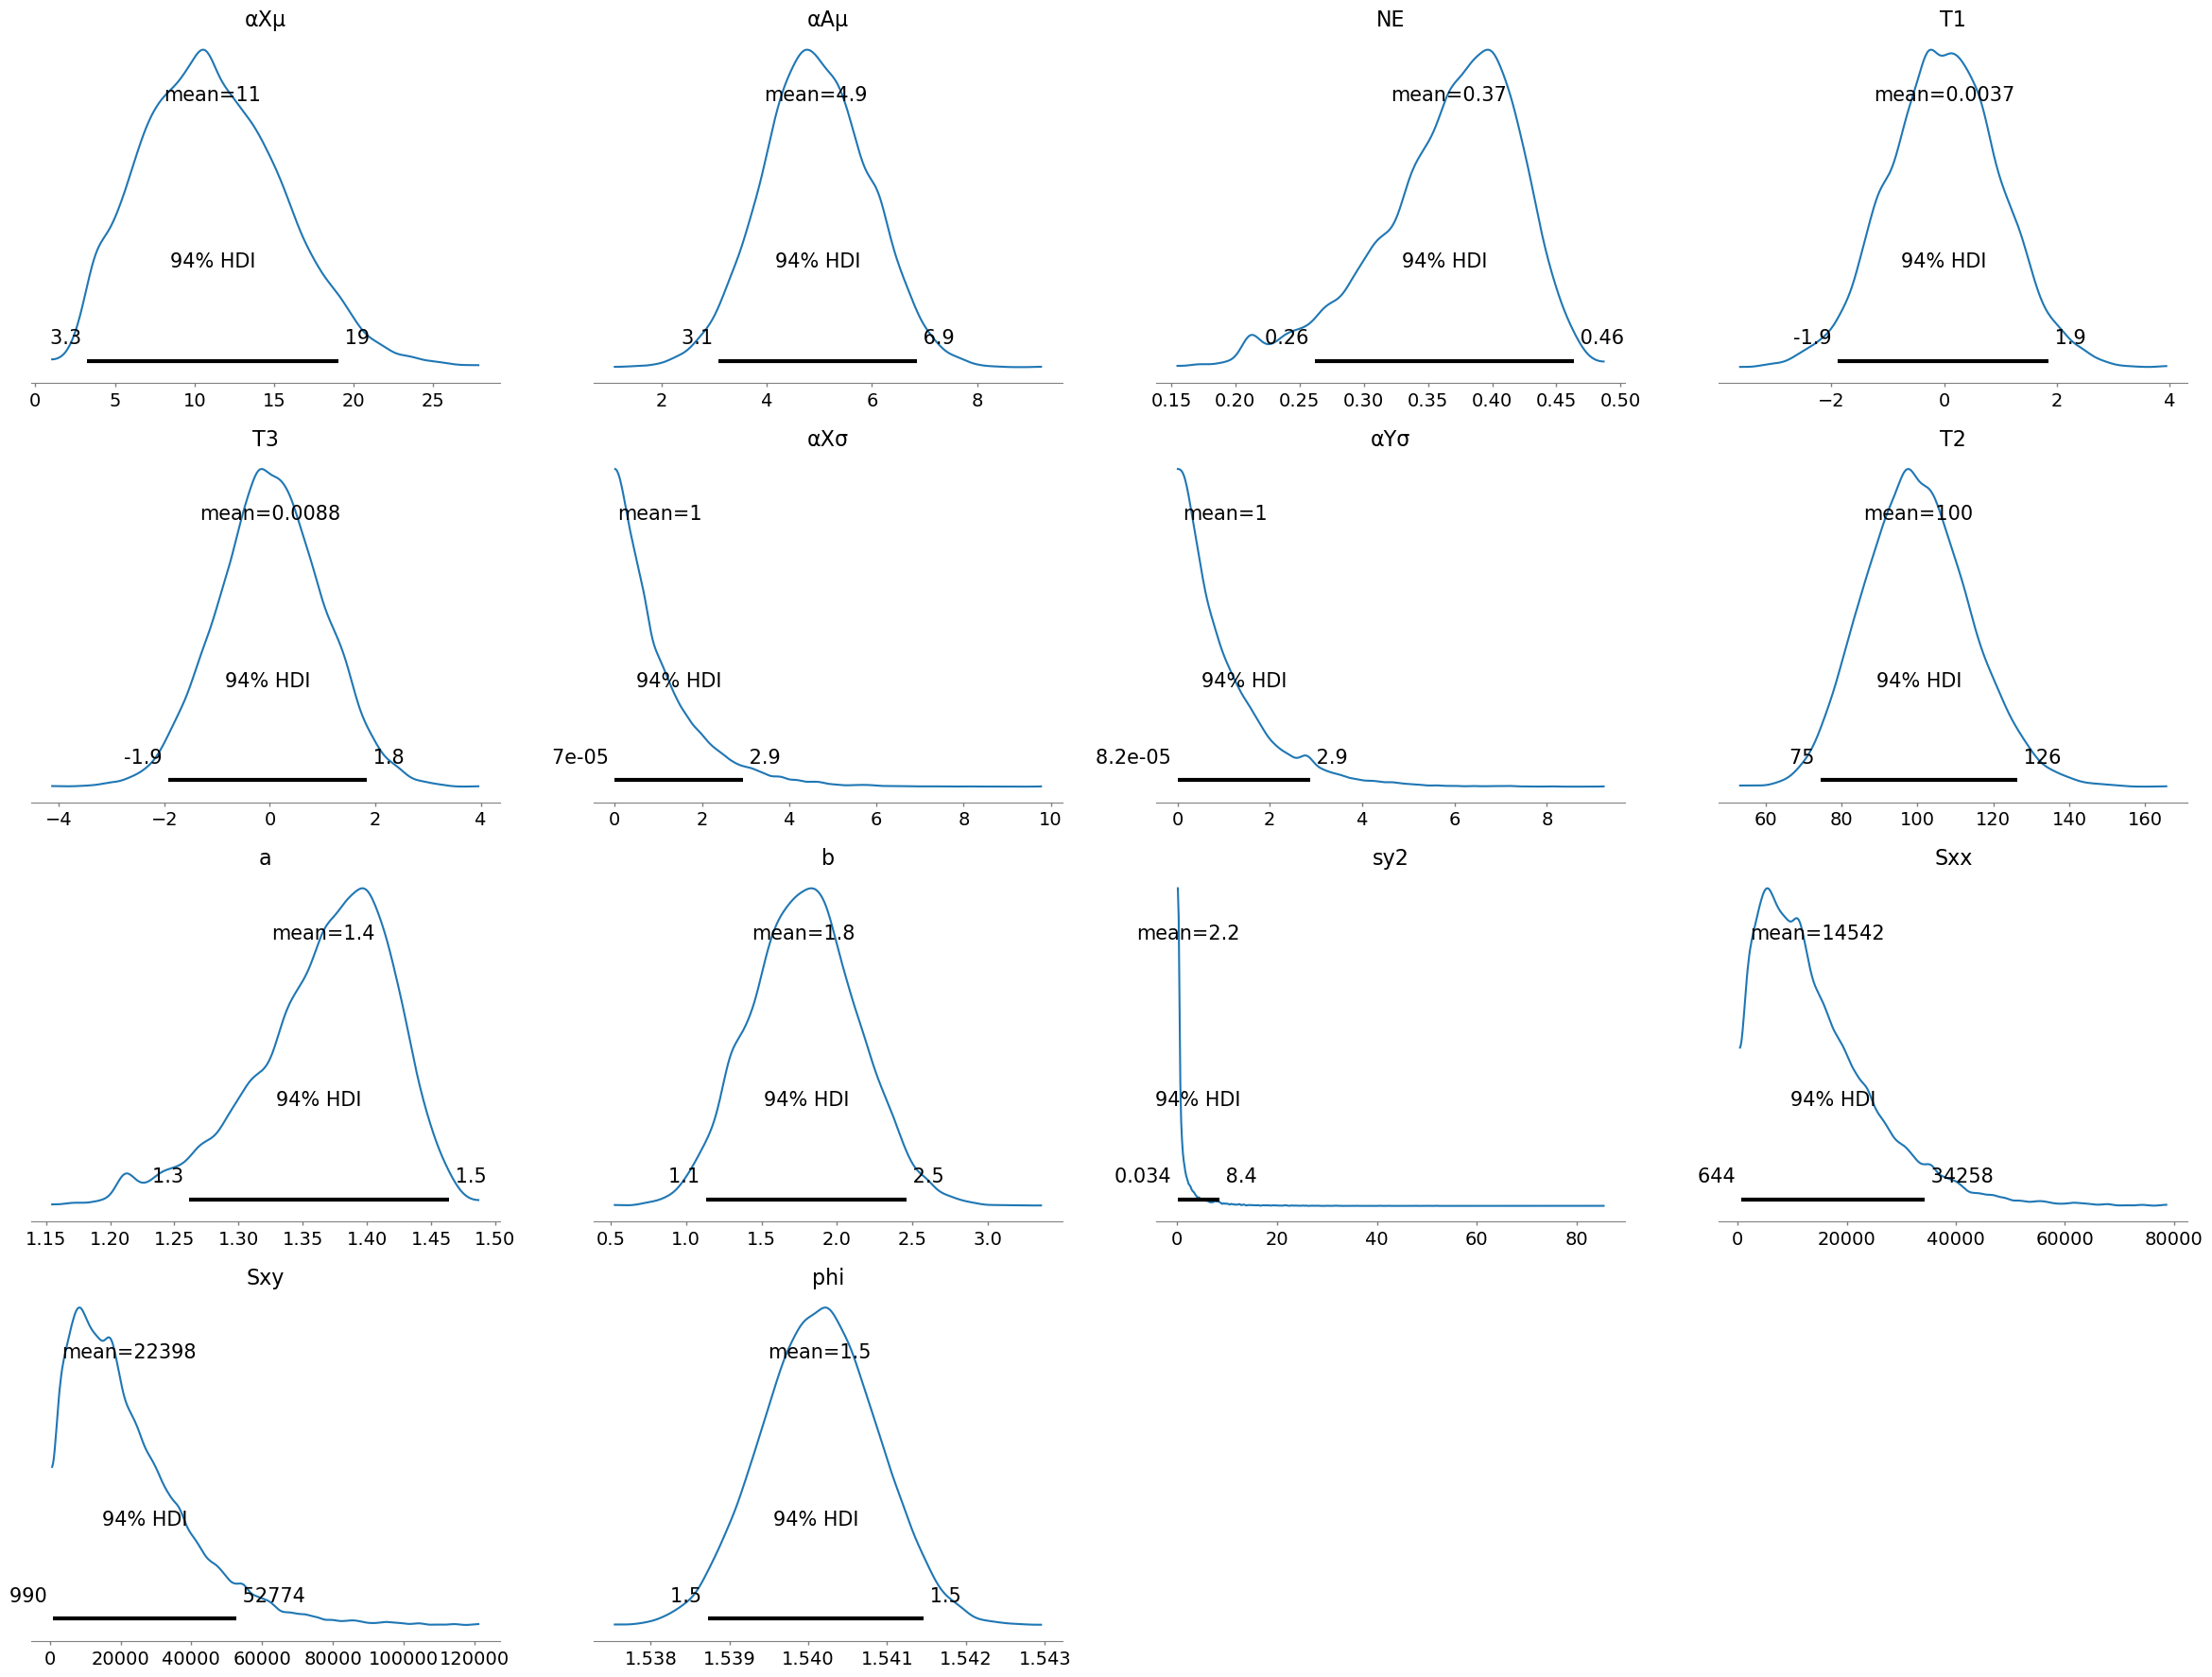

In [24]:
az.plot_posterior(
    trace, 
    # filter_vars=""
)

/home/fausto/mambaforge/envs/users_prediction/lib/python3.13/site-packages/arviz/plots/backends/matplotlib/pairplot.py:233: UserWarning: rcParams['plot.max_subplots'] (40) is smaller than the number of resulting pair plots with these variables, generating only a 8x8 grid
  warnings.warn(


array([[<Axes: ylabel='αAμ'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='NE'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='T1'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='T3'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='αXσ'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='αYσ'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >],
       [<Axes: ylabel='T2'>, <Axes: >, <Axes: >, <Axes: >, <Axes: >,
        <Axes: >, <Axes: >, <Axes: >],
       [<Axes: xlabel='αXμ', ylabel='a'>, <Axes: xlabel='αAμ'>,
        <Axes: xlabel='NE'>, <Axes: xlabel='T1'>, <Axes: xlabel='T3'>,
        <Axes: xlabel='αXσ'>, <Axes: xlabel='αYσ'>, <Axes: xlabel='T2'>]],
      dtype=object)

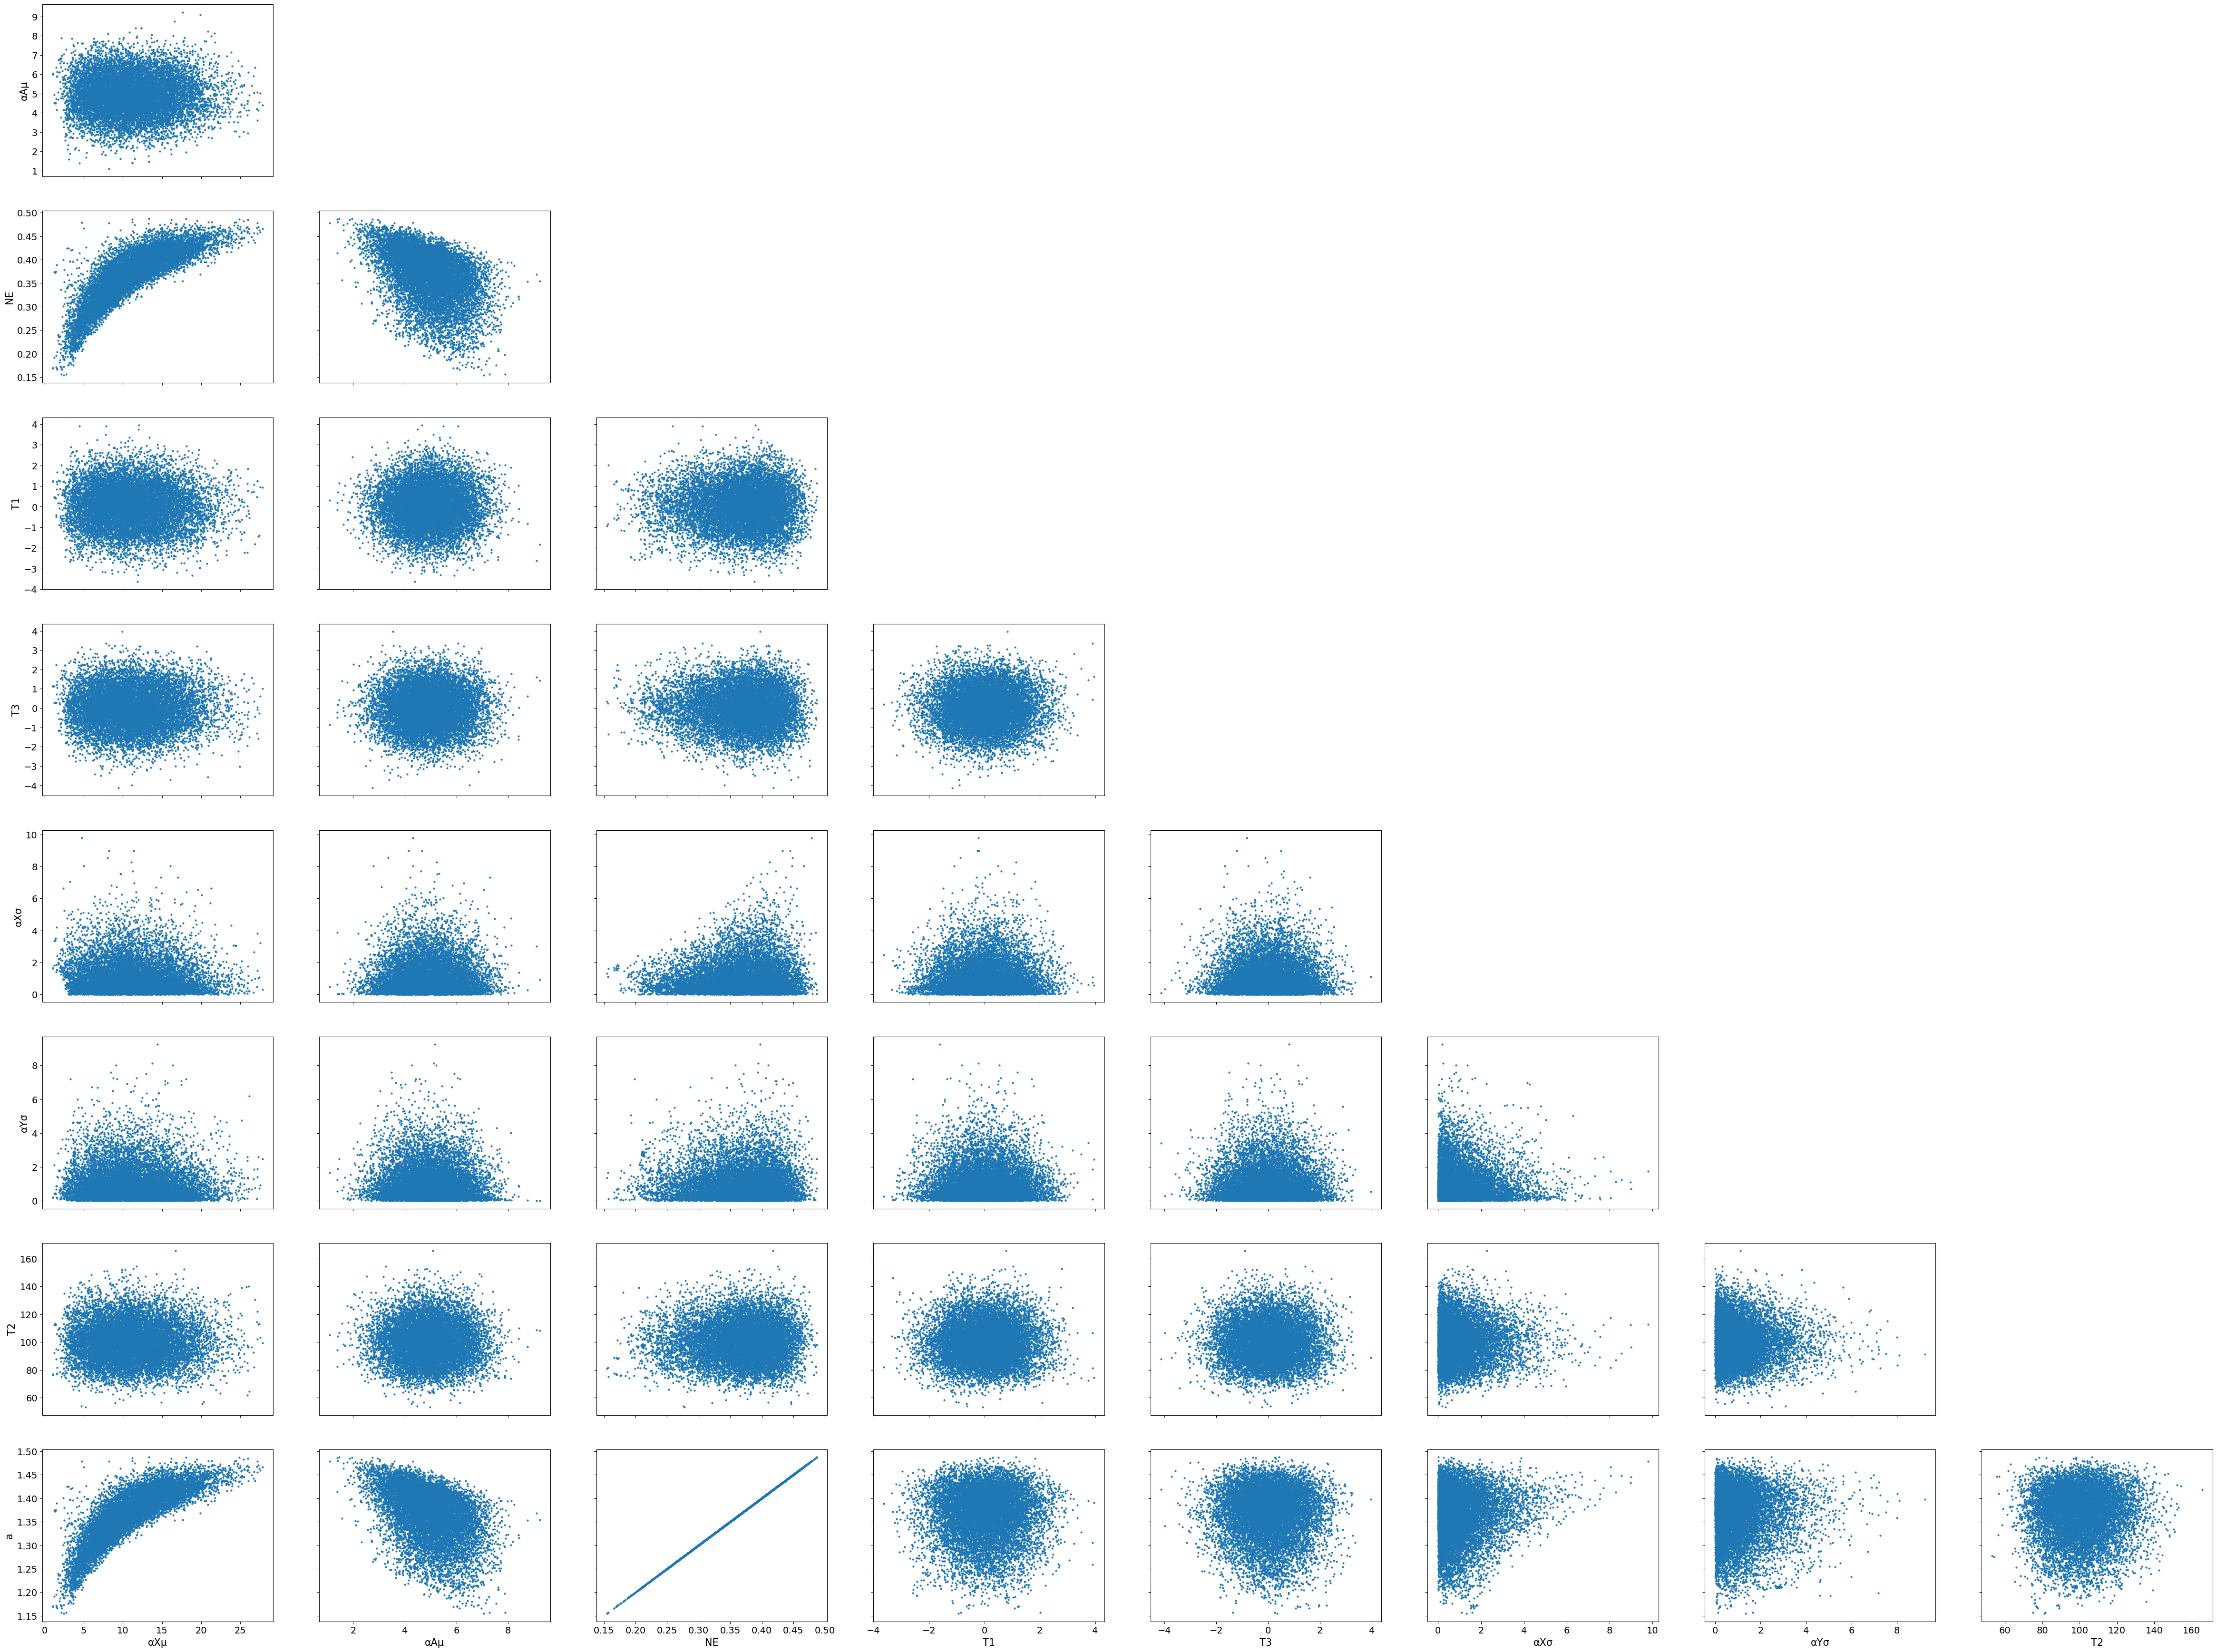

In [25]:
az.plot_pair(trace)

In [5]:
rng = np.random.default_rng(123)

# one predictive sample per posterior draw
Xnew_samples   = rng.normal(loc=trace.posterior['αXμ'],
                            scale=trace.posterior['αXσ'])

phi_samples    = trace.posterior['phi']
Prednew_samples = phi_samples * Xnew_samples

# Shape (chains, draws); flatten if you wish
pred_vec = np.asarray(Prednew_samples).ravel()

In [12]:
Prednew_samples.shape

(4, 3000)

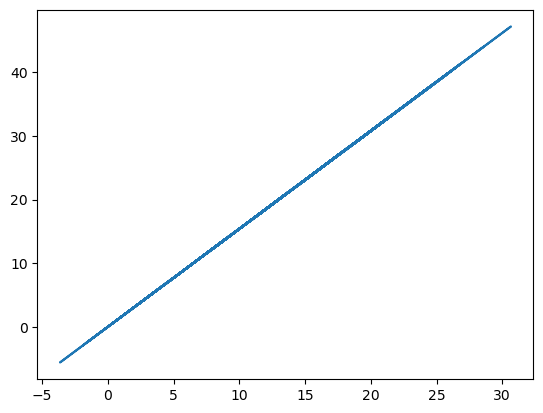

In [13]:
plt.plot(Xnew_samples.flatten(), pred_vec)

In [38]:
trace.posterior.keys()

KeysView(<xarray.Dataset> Size: 1MB
Dimensions:  (chain: 4, draw: 3000)
Coordinates:
  * chain    (chain) int64 32B 0 1 2 3
  * draw     (draw) int64 24kB 0 1 2 3 4 5 6 ... 2994 2995 2996 2997 2998 2999
Data variables: (12/14)
    αXμ      (chain, draw) float64 96kB 14.38 10.77 8.82 ... 16.09 6.495 5.794
    αAμ      (chain, draw) float64 96kB 4.657 5.21 3.771 ... 7.53 2.604 3.626
    NE       (chain, draw) float64 96kB 0.4067 0.3726 0.379 ... 0.3878 0.331
    T1       (chain, draw) float64 96kB -1.762 -1.186 0.8955 ... -0.3576 -1.431
    T3       (chain, draw) float64 96kB 1.442 0.7549 -0.8443 ... 0.6408 0.6675
    αXσ      (chain, draw) float64 96kB 0.9285 3.729 0.09203 ... 1.387 0.805
    ...       ...
    a        (chain, draw) float64 96kB 1.407 1.373 1.379 ... 1.368 1.388 1.331
    b        (chain, draw) float64 96kB 1.894 1.941 1.429 ... 2.768 1.01 1.2
    sy2      (chain, draw) float64 96kB 0.2573 2.906 0.2868 ... 1.664 0.2641
    Sxx      (chain, draw) float64 96kB 2.029e+04 1

In [36]:
df = trace.posterior['NE', ].to_dataframe()

In [35]:
NE = df.reset_index(drop=True)

In [ ]:
Y = 0.5 * X + NE * A + N_Y

In [39]:
from dataclasses import dataclass
from typing import Tuple

In [49]:
# ---------- helpers ----------
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

@dataclass
class BinaryASCM:
    alpha_x_mu: float      # μ of N_X
    alpha_x_sigma: float   # σ of N_X        (σ > 0)
    alpha_a_mu: float      # shift in log-odds of A (≡ α_{A μ})
    alpha_y_sigma: float   # σ of N_Y        (σ > 0)
    n_e: float             # coefficient N_E   (e.g. −0.5)

    # ----------------------------------------------------------
    #    Observational sampling
    # ----------------------------------------------------------
    def sample(self, n: int = 1, random_state=None
              ) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
        rng = np.random.default_rng(random_state)

        # exogenous noise
        N_X = rng.normal(self.alpha_x_mu, self.alpha_x_sigma, size=n)
        N_Y = rng.normal(0.0,             self.alpha_y_sigma, size=n)
        N_A = rng.normal(self.alpha_a_mu, 1.0, size=n)          # U_A ~ Uniform(0,1)

        # endogenous variables
        X = N_X
        A = 0.5 * X + N_A
        Y = 0.5 * X + self.n_e * A + N_Y
        return X, A, Y

    # ----------------------------------------------------------
    #    Intervene on A :  do(A = a_fixed ∈ {0,1})
    # ----------------------------------------------------------
    def do_A(self,
             a_fixed,               # scalar 0 or 1, or array with X.shape
             X: np.ndarray,
             n: int = 1,
             random_state=None
            ) -> np.ndarray:
        """
        Returns an array `Y_do` with shape  (n, *X.shape),
        each row an i.i.d. sample from  Y | do(A=a_fixed), X.
        """
        if np.any((np.asarray(a_fixed) != 0) & (np.asarray(a_fixed) != 1)):
            raise ValueError("a_fixed must be 0 or 1 (binary).")

        rng = np.random.default_rng(random_state)
        X = np.asarray(X)
        a_fixed = np.asarray(a_fixed)

        if a_fixed.shape == ():                  # broadcast scalar
            a_fixed = np.full_like(X, a_fixed)
        if a_fixed.shape != X.shape:
            raise ValueError("`a_fixed` and `X` must have the same shape "
                             "or `a_fixed` must be scalar.")

        N_Y = rng.normal(0.0, self.alpha_y_sigma, size=(n,) + X.shape)
        Y_do = 0.5 * X[None, ...] + self.n_e * a_fixed[None, ...] + N_Y
        return Y_do

    # ----------------------------------------------------------
    #    Closed-form distribution of  Y | do(A=a), X
    # ----------------------------------------------------------
    def analytic_do_distribution(self, a_fixed, X
                                ) -> Tuple[np.ndarray, float]:
        """
        Mean μ(X,a_fixed) and variance σ² of  Y | do(A=a_fixed), X.
            μ = 0.5·X + n_e·a_fixed
            σ² = (alpha_y_sigma)²       (independent of X and a_fixed)
        """
        a_fixed = np.asarray(a_fixed)
        mu = 0.5 * np.asarray(X) + self.n_e * a_fixed
        var = self.alpha_y_sigma ** 2
        return mu, var

    # ----------------------------------------------------------
    #    Optional helper:   P(A=1 | X)
    # ----------------------------------------------------------
    def p_A_eq_1_given_X(self, X):
        """Returns the observational probability that A=1 given X."""
        return sigmoid(np.asarray(X) + self.alpha_a_mu)

# looping over different parameters of the SCM
def estimate_cate_from_row(row, *, n_mc: int = 0, seed: int | None = None):
    """
    row … a Series from df_params  (one set of α's and n_e)

    n_mc = 0    → analytic CATE   (fast, exact)
    n_mc > 0    → Monte-Carlo CATE, using n_mc draws of X
    """
    scm = BinaryASCM(
        alpha_x_mu   = row["αXμ"],
        alpha_x_sigma= row["αXσ"],
        alpha_a_mu   = row["αAμ"],
        alpha_y_sigma= row["αYσ"],
        n_e          = row["NE"],
    )

    # --- analytic version ----------------------------------
    if n_mc == 0:
        # In this SCM  CATE(X) = E[Y|do(A=1),X] − E[Y|do(A=0),X] = n_e
        return scm.n_e

    # --- Monte-Carlo version -------------------------------
    rng = np.random.default_rng(seed)
    X, *_ = scm.sample(n=n_mc, random_state=rng)
    mu1, _ = scm.analytic_do_distribution(1, X)
    mu0, _ = scm.analytic_do_distribution(0, X)
    return (mu1 - mu0).mean()

# Analytic (exact, fastest)
df_params = trace.posterior.to_dataframe()
df_params["cate"] = df_params.apply(estimate_cate_from_row, axis=1)

cate_vector = df_params["cate"].to_numpy()
print(cate_vector)

[0.40673577 0.37258432 0.3789608  ... 0.36764744 0.38783864 0.33099786]


(array([  25.,  202.,  310.,  609., 1183., 1955., 2886., 3101., 1491.,
         238.]),
 array([0.15450013, 0.18776252, 0.2210249 , 0.25428729, 0.28754967,
        0.32081206, 0.35407445, 0.38733683, 0.42059922, 0.4538616 ,
        0.48712399]),
 <BarContainer object of 10 artists>)

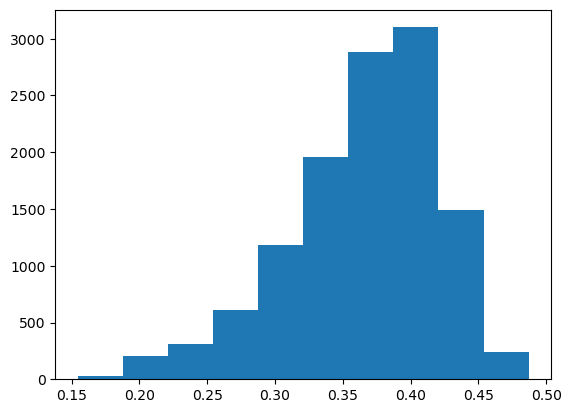

In [50]:
plt.hist(cate_vector)

# Binary A

In [14]:
from pytensor.tensor import log1p, softplus, sigmoid, logaddexp, dot

In [11]:
# constants
n         = 8000
Xo_obs    = 1.37
Predo_obs = 2.11
tiny      = 1e-3

with pm.Model() as m:
    # hyper-priors
    αXμ = pm.Normal('αXμ', 10, 5)
    αXσ = pm.Exponential('αXσ', 1)
    αAμ = pm.Normal('αAμ', 5, 1)
    αYσ = pm.Exponential('αYσ', 1)
    NE  = pm.Normal('NE', -0.1, 1)

    # latent (X_i, Y_i) — still size-n
    X = pm.Normal('X', αXμ, αXσ, shape=n)
    Y = pm.Normal('Y', 0, 10, shape=n)          # diffuse prior

    # ---- binary-A marginal likelihood ---------------------------------
    mu0   = X
    mu1   = X + NE
    logp0 = pm.logp(pm.Normal.dist(mu=mu0, sigma=αYσ), Y)
    logp1 = pm.logp(pm.Normal.dist(mu=mu1, sigma=αYσ), Y)
    logit_pi = X + αAμ
    
    pm.Potential('mixlike',
        pm.math.logaddexp(log1p(-sigmoid(logit_pi)) + logp0,
                          softplus(logit_pi)                + logp1))

    # analytic φ* based on X and Y  (still valid!)
    phi = pm.Deterministic('phi', pm.math.dot(X, Y) / pm.math.dot(X, X))

    # observed pair (X^o, Pred^o)
    pm.Normal('Predo',
              mu = phi * Xo_obs,
              sigma = tiny,
              observed = Predo_obs)

    trace = pm.sample(2000, target_accept=.99, chains=4)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [αXμ, αXσ, αAμ, αYσ, NE, X, Y]


Output()

Sampling 4 chains for 1_000 tune and 330 draw iterations (4_000 + 1_320 draws total) took 796 seconds.
Chain 0 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 1 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 2 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 3 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


In [12]:
trace

Inference data with groups:
	> posterior
	> sample_stats
	> observed_data

In [19]:
n         = 500
Xo_obs    = 1.37
Predo_obs = 2.11
sigma_P   = 0.05          # <- not 1e-3 !
rng       = np.random.default_rng(1)

with pm.Model() as m:

    # ─── hyper-priors ──────────────────────────────────────────
    αXμ  = pm.Normal('αXμ',  10, 5)
    αXσ  = pm.HalfNormal('αXσ', 2)      # narrower, keeps funnel shallow
    αAμ  = pm.Normal('αAμ',   5, 1)
    αYσ  = pm.HalfNormal('αYσ', 2)
    NE   = pm.Normal('NE',  -0.1, 0.5)  # slightly tighter

    # ─── NON-CENTRED latent plate ─────────────────────────────
    X_raw = pm.Normal('X_raw',  0, 1, shape=n)
    X     = pm.Deterministic('X', αXμ + αXσ * X_raw)

    # Y: centre it at X + E[A|X]·N_E  (optional but helps)
    mu_Y  = X + (sigmoid(X + αAμ) * NE)
    Y_raw = pm.Normal('Y_raw', 0, 1, shape=n)
    Y     = pm.Deterministic('Y', mu_Y + αYσ * Y_raw)

    # ─── binary-A marginal likelihood (log-mix) ───────────────
    mu0   = X
    mu1   = X + NE
    logp0 = pm.logp(pm.Normal.dist(mu=mu0,  sigma=αYσ), Y)
    logp1 = pm.logp(pm.Normal.dist(mu=mu1,  sigma=αYσ), Y)
    pi    = sigmoid(X + αAμ)
    pm.Potential('mixlike',
        logaddexp(log1p(-pi) + logp0,
                  pm.math.log(pi)    + logp1))

    # ─── analytic φ*  and the observed pair ───────────────────
    phi = pm.Deterministic('phi', dot(X, Y) / dot(X, X))
    pm.Normal('Predo',
              mu = phi * Xo_obs,
              sigma = sigma_P,
              observed = Predo_obs)

    trace = pm.sample(2_000,
                      target_accept=0.95,
                      # max_treedepth=15,
                      init='jitter+adapt_diag',
                      random_seed=42)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [αXμ, αXσ, αAμ, αYσ, NE, X_raw, Y_raw]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 419 seconds.
Chain 0 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 1 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 2 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 3 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


In [20]:
trace

Inference data with groups:
	> posterior
	> sample_stats
	> observed_data

/home/fausto/mambaforge/envs/users_prediction/lib/python3.13/site-packages/arviz/plots/plot_utils.py:270: UserWarning: rcParams['plot.max_subplots'] (40) is smaller than the number of variables to plot (2006) in plot_posterior, generating only 40 plots
  warnings.warn(


array([[<Axes: title={'center': 'αXμ'}>, <Axes: title={'center': 'αAμ'}>,
        <Axes: title={'center': 'NE'}>,
        <Axes: title={'center': 'X_raw\n0'}>],
       [<Axes: title={'center': 'X_raw\n1'}>,
        <Axes: title={'center': 'X_raw\n2'}>,
        <Axes: title={'center': 'X_raw\n3'}>,
        <Axes: title={'center': 'X_raw\n4'}>],
       [<Axes: title={'center': 'X_raw\n5'}>,
        <Axes: title={'center': 'X_raw\n6'}>,
        <Axes: title={'center': 'X_raw\n7'}>,
        <Axes: title={'center': 'X_raw\n8'}>],
       [<Axes: title={'center': 'X_raw\n9'}>,
        <Axes: title={'center': 'X_raw\n10'}>,
        <Axes: title={'center': 'X_raw\n11'}>,
        <Axes: title={'center': 'X_raw\n12'}>],
       [<Axes: title={'center': 'X_raw\n13'}>,
        <Axes: title={'center': 'X_raw\n14'}>,
        <Axes: title={'center': 'X_raw\n15'}>,
        <Axes: title={'center': 'X_raw\n16'}>],
       [<Axes: title={'center': 'X_raw\n17'}>,
        <Axes: title={'center': 'X_raw\n18'}>

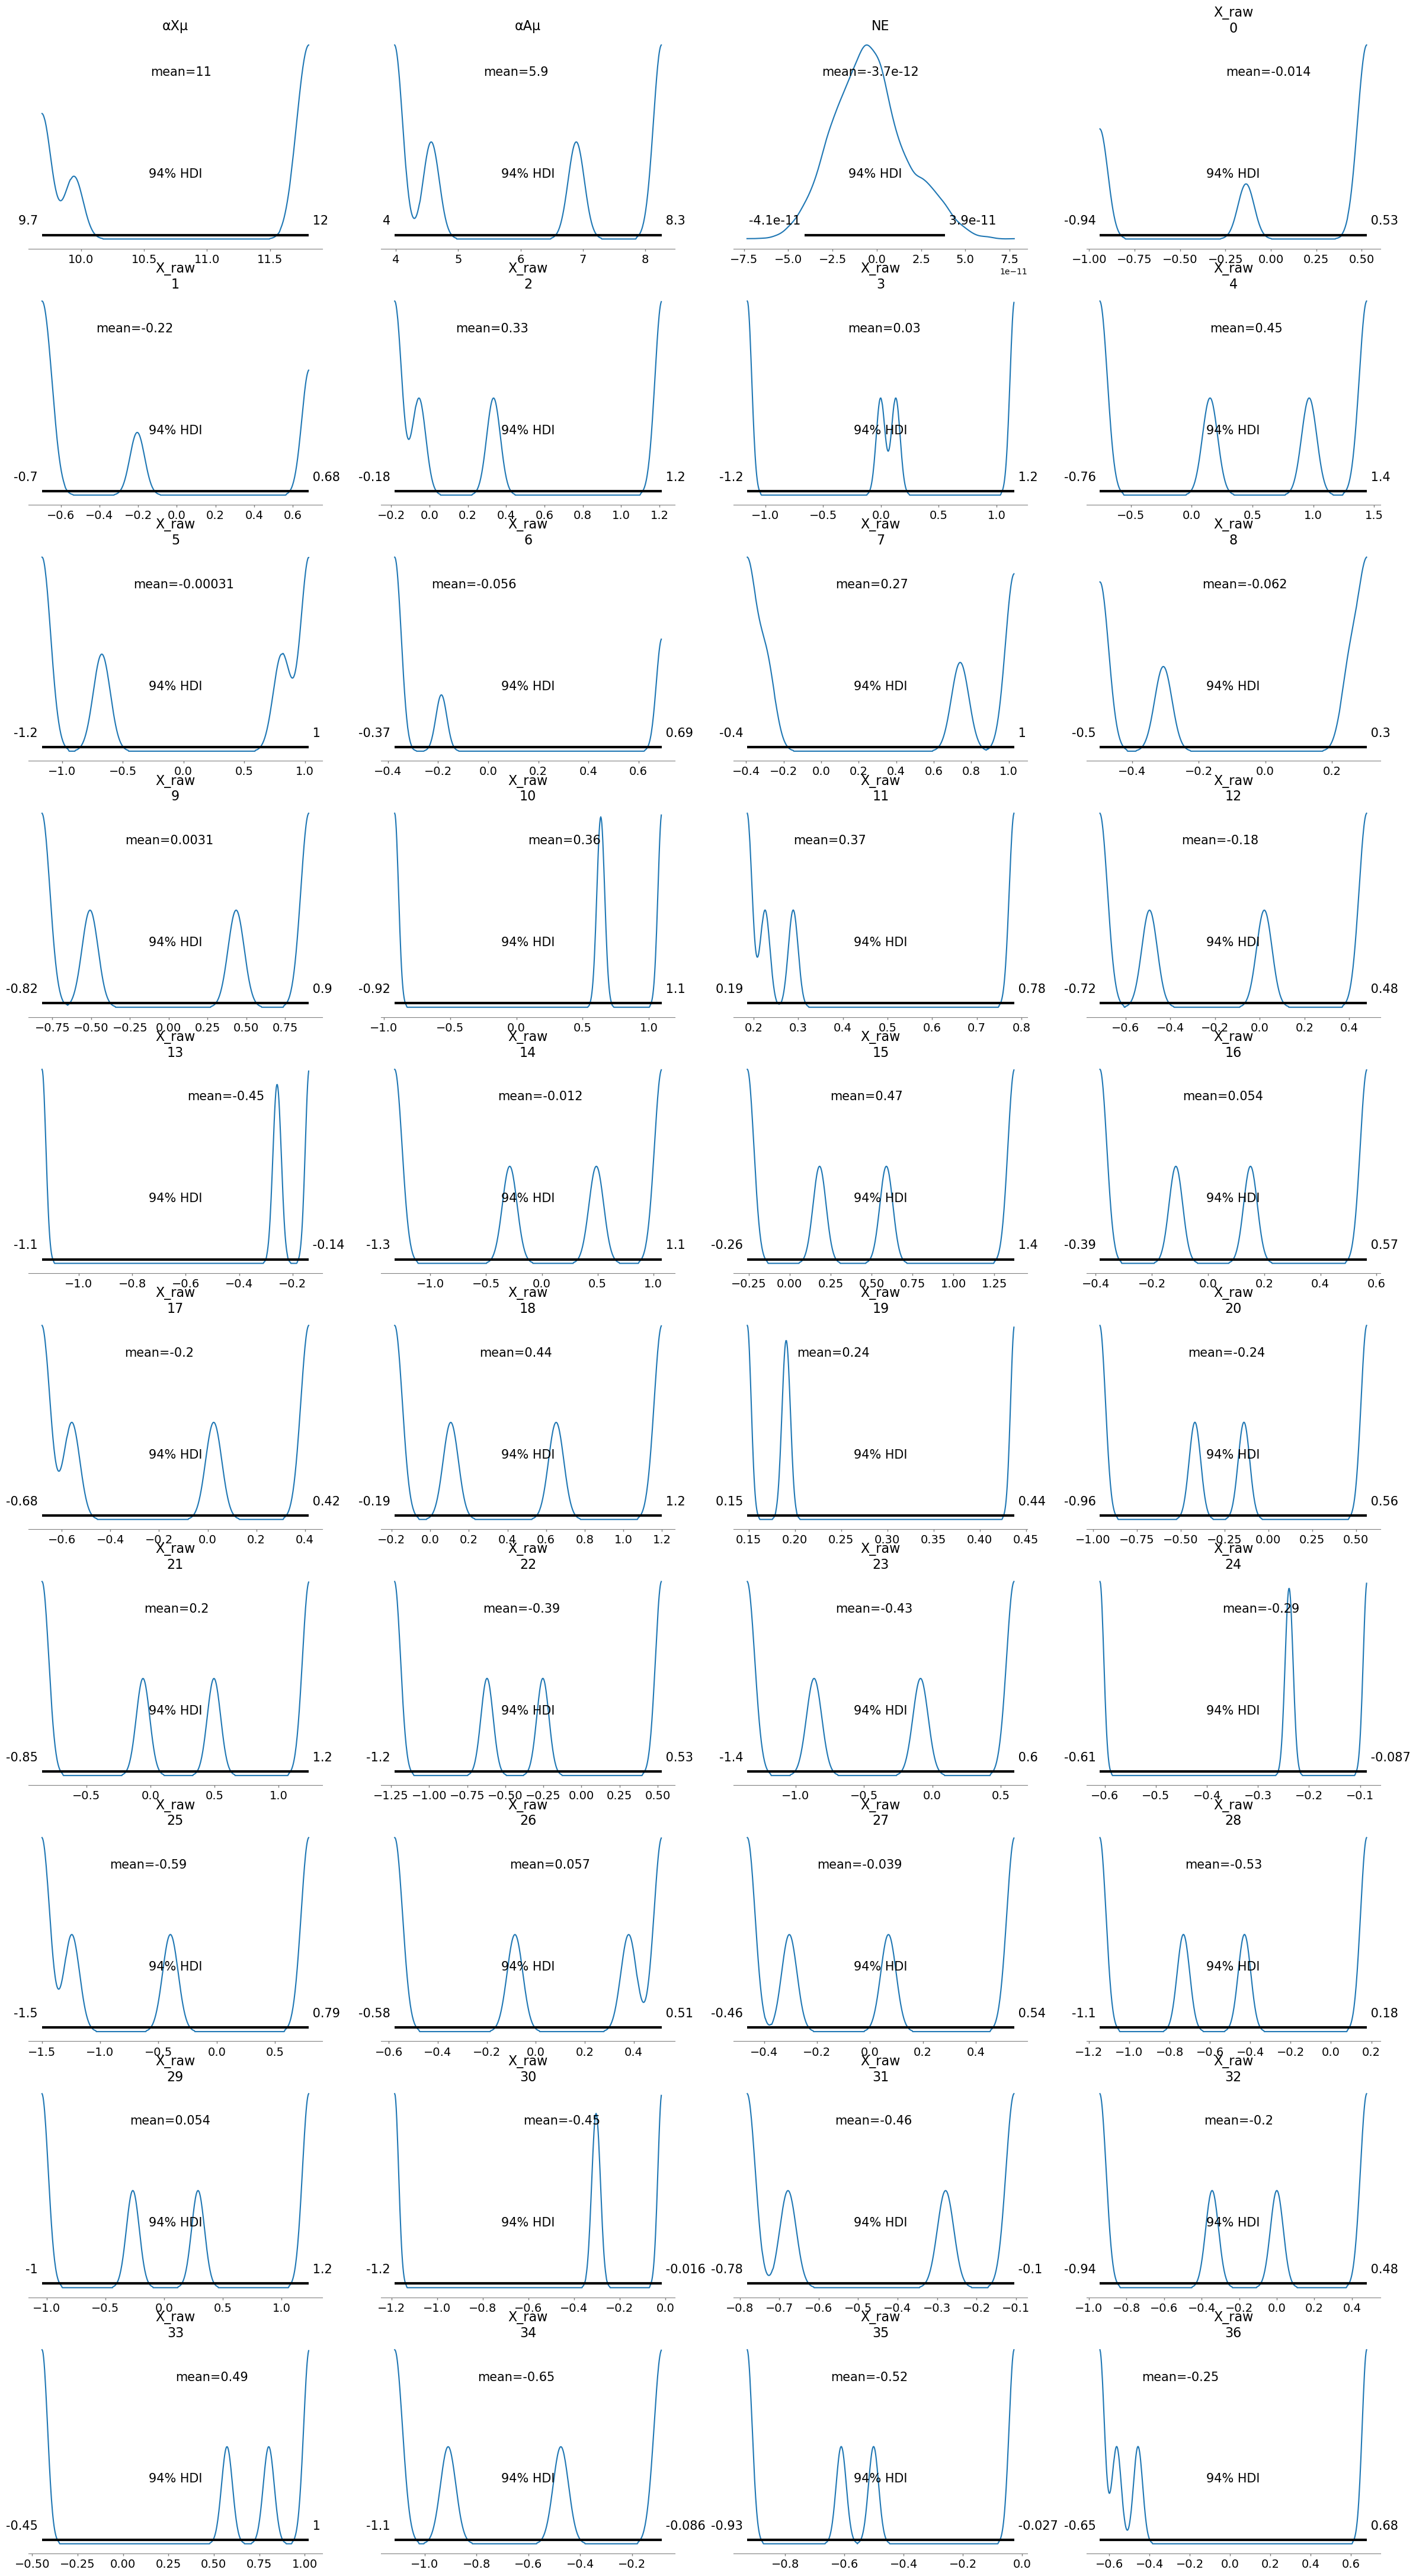

In [21]:
az.plot_posterior(trace)